# Time Series and Date Handling in Pandas

Time series are measurements in time order: daily temperatures, hourly trips, monthly sales. pandas has a complete toolkit for them: datetime indexes, resampling, rolling windows, shifts, time zones and calendar offsets.

**After this lesson you can:**

1. Parse dates and build a `DatetimeIndex`.
2. Resample to other frequencies (downsampling and upsampling).
3. Compute rolling and expanding statistics, shifts, differences and percent changes.
4. Handle time zones and calendar offsets (business days, month ends).
5. Decompose a series into trend and seasonality.

**Data:** Seattle daily weather 2012–2015 (NOAA) and NYC taxi trips, January 2024.

In [1]:
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(Path.cwd().parent / "tools"))
import datasets                                   # course helper: downloads pinned public datasets

weather = pd.read_csv(datasets.fetch("seattle-weather.csv"), parse_dates=["date"]).set_index("date")
step = weather.index.to_series().diff().value_counts().index[0]
print(weather.index.dtype, "| from", weather.index.min().date(), "to", weather.index.max().date(), "| step between rows:", step)
weather.head(3)

datetime64[us] | from 2012-01-01 to 2015-12-31 | step between rows: 1 days 00:00:00


,precipitation,temp_max,temp_min,wind,weather
date,,,,,
2012-01-01,0.0,12.8,5.0,4.7,drizzle
2012-01-02,10.9,10.6,2.8,4.5,rain
2012-01-03,0.8,11.7,7.2,2.3,rain


## 1. Selecting by Date

A `DatetimeIndex` supports **partial string indexing**: `"2014"` selects a year, `"2014-07"` a month, and slices select ranges.

In [2]:
print("rows in 2014     :", len(weather.loc["2014"]))
print("July 2014 max    :", weather.loc["2014-07", "temp_max"].max(), "°C")
print("rain in Q4 2015  :", weather.loc["2015-10":"2015-12", "precipitation"].sum().round(1), "mm")
print("weekdays of the first days:", weather.index[:3].day_name().tolist())

rows in 2014     : 365
July 2014 max    : 34.4 °C
rain in Q4 2015  : 619.5 mm
weekdays of the first days: ['Sunday', 'Monday', 'Tuesday']


## 2. Resampling

`resample(rule)` groups by time intervals. **Downsampling** (daily → monthly) needs an aggregation; **upsampling** (daily → hourly) needs a fill method.

| Rule | Interval |
| :--- | :--- |
| `"h"`, `"D"`, `"W"` | hour, day, week (ending Sunday) |
| `"MS"` / `"ME"` | month start / month end labels |
| `"QE"`, `"YE"` | quarter end, year end |

In [3]:
monthly = weather.resample("MS").agg({"temp_max": "mean", "temp_min": "mean", "precipitation": "sum",
                                      "weather": lambda s: (s == "sun").mean()})
monthly.columns = ["temp_max_mean", "temp_min_mean", "rain_mm", "sunny_share"]
print(monthly.head(3).round(2), "\n")
upsampled = weather["temp_max"].loc["2015-01-04":"2015-01-05"].resample("6h").interpolate()
print("upsampled to 6 hours with interpolation:\n", upsampled)

            temp_max_mean  temp_min_mean  rain_mm  sunny_share
date                                                          
2012-01-01           7.05           1.54    173.3         0.13
2012-02-01           9.28           3.20     92.3         0.28
2012-03-01           9.55           2.84    183.0         0.19 

upsampled to 6 hours with interpolation:
 date
2015-01-04 00:00:00    10.6
2015-01-04 06:00:00    11.0
2015-01-04 12:00:00    11.4
2015-01-04 18:00:00    11.8
2015-01-05 00:00:00    12.2
Freq: 6h, Name: temp_max, dtype: float64


## 3. Rolling Windows, Shifts and Changes

| Method | Meaning |
| :--- | :--- |
| `rolling(30).mean()` | mean of the last 30 rows (or `rolling("30D")` for 30 days of time) |
| `expanding().max()` | running maximum since the start |
| `shift(1)` | the previous value |
| `diff()` | value − previous value |
| `pct_change()` | relative change |

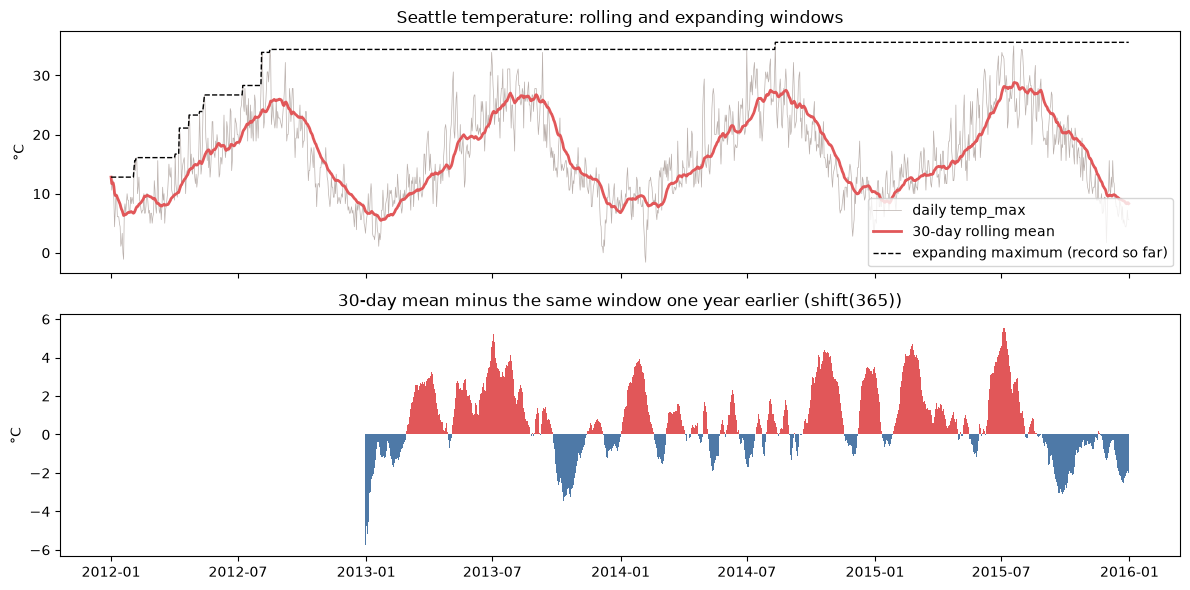

warmest 30-day window: ending 2015-07-20 at 28.8 °C


In [4]:
t = weather["temp_max"]
smooth = t.rolling("30D").mean()
record = t.expanding().max()
yoy = t.rolling("30D").mean() - t.rolling("30D").mean().shift(365)
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
ax1.plot(t.index, t, lw=0.5, color="#BAB0AC", label="daily temp_max")
ax1.plot(smooth.index, smooth, lw=2, color="#E15759", label="30-day rolling mean")
ax1.plot(record.index, record, lw=1, color="black", ls="--", label="expanding maximum (record so far)")
ax1.set(ylabel="°C", title="Seattle temperature: rolling and expanding windows")
ax1.legend(loc="lower right")
ax2.bar(yoy.index, yoy, width=1, color=np.where(yoy > 0, "#E15759", "#4E79A7"))
ax2.set(ylabel="°C", title="30-day mean minus the same window one year earlier (shift(365))")
plt.tight_layout()
plt.show()
print(f"warmest 30-day window: ending {smooth.idxmax().date()} at {smooth.max():.1f} °C")

## 4. Seasonality and Decomposition

A **seasonal decomposition** splits a series into **trend**, **seasonal** pattern and **residual**. The monthly mean temperature has a strong yearly cycle (period 12).

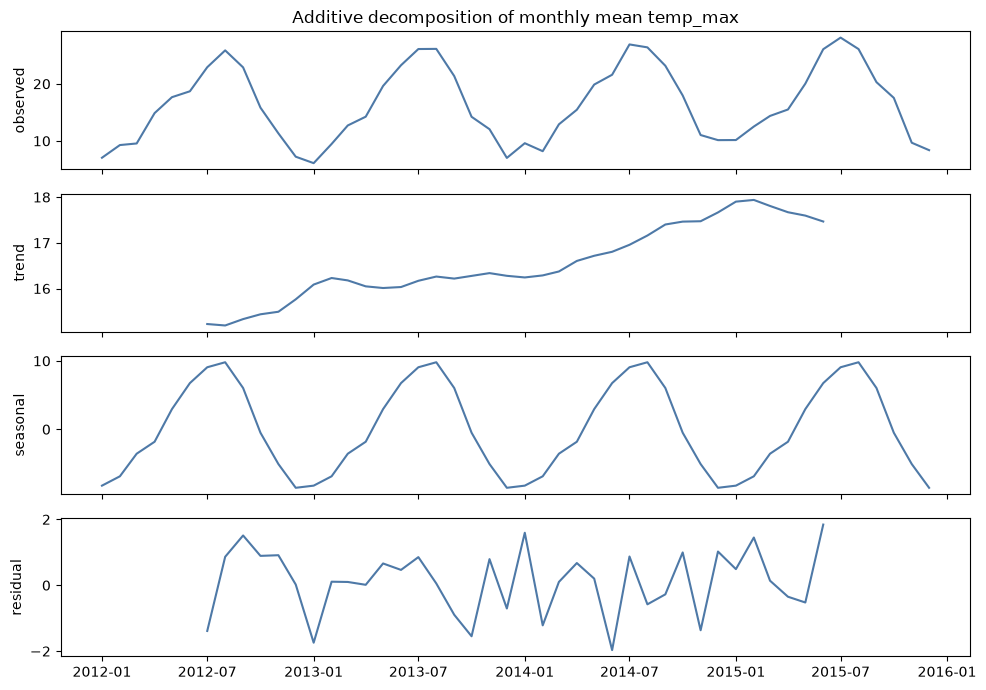

seasonal swing: 18.4 °C between the warmest and the coldest month


In [5]:
from statsmodels.tsa.seasonal import seasonal_decompose

dec = seasonal_decompose(monthly["temp_max_mean"], model="additive", period=12)
fig, axes = plt.subplots(4, 1, figsize=(10, 7), sharex=True)
for ax, (name, series) in zip(axes, [("observed", dec.observed), ("trend", dec.trend), ("seasonal", dec.seasonal),
                                     ("residual", dec.resid)]):
    ax.plot(series.index, series, color="#4E79A7")
    ax.set_ylabel(name)
axes[0].set_title("Additive decomposition of monthly mean temp_max")
plt.tight_layout()
plt.show()
print(f"seasonal swing: {dec.seasonal.max() - dec.seasonal.min():.1f} °C between the warmest and the coldest month")

## 5. Time Zones

Timestamps without a time zone are **naive**. The NYC taxi data records local New York time. `tz_localize` attaches a zone; `tz_convert` converts to another one. Store and exchange timestamps in UTC; convert to local time for display.

In [6]:
trips = pd.read_parquet(datasets.taxi("2024-01"), columns=["tpep_pickup_datetime", "fare_amount"])
trips = trips[trips["tpep_pickup_datetime"].between("2024-01-01", "2024-02-01", inclusive="left")]
local = trips["tpep_pickup_datetime"].dt.tz_localize("America/New_York")
utc = local.dt.tz_convert("UTC")
istanbul = local.dt.tz_convert("Europe/Istanbul")
fmt = "%Y-%m-%d %H:%M %Z"
print(pd.DataFrame({"naive": trips["tpep_pickup_datetime"].head(2).dt.strftime("%Y-%m-%d %H:%M"),
                    "New York": local.head(2).dt.strftime(fmt), "UTC": utc.head(2).dt.strftime(fmt),
                    "Istanbul": istanbul.head(2).dt.strftime(fmt)}).T)

dst = pd.Series(pd.date_range("2024-03-10 00:00", periods=5, freq="h", tz="America/New_York"))
print("\nDST change in New York (2:00 does not exist on 10 March 2024):")
print(dst.dt.strftime("%Y-%m-%d %H:%M %Z").tolist())

                             0                     1
naive         2024-01-01 00:57      2024-01-01 00:03
New York  2024-01-01 00:57 EST  2024-01-01 00:03 EST
UTC       2024-01-01 05:57 UTC  2024-01-01 05:03 UTC
Istanbul  2024-01-01 08:57 +03  2024-01-01 08:03 +03

DST change in New York (2:00 does not exist on 10 March 2024):
['2024-03-10 00:00 EST', '2024-03-10 01:00 EST', '2024-03-10 03:00 EDT', '2024-03-10 04:00 EDT', '2024-03-10 05:00 EDT']


## 6. Calendar Offsets

Offsets know the calendar: `pd.offsets.BDay()` (business day), `MonthEnd()`, `Week(weekday=0)`. `pd.bdate_range` creates business-day ranges.

In [7]:
d = pd.Timestamp("2024-01-31")
print("next business day after Fri 2 Feb  :", (pd.Timestamp("2024-02-02") + pd.offsets.BDay()).date())
print("end of the month after 31 Jan      :", (d + pd.offsets.MonthEnd()).date())
print("business days in January 2024      :", len(pd.bdate_range("2024-01-01", "2024-01-31")))

hourly = trips.set_index("tpep_pickup_datetime").resample("h").size()
by_kind = hourly.groupby(np.where(hourly.index.day_of_week < 5, "weekday", "weekend")).mean()
print("\nmean trips per hour:", by_kind.round(0).to_dict())

next business day after Fri 2 Feb  : 2024-02-05
end of the month after 31 Jan      : 2024-02-29
business days in January 2024      : 23



mean trips per hour: {'weekday': 3993.0, 'weekend': 3961.0}


*Insight: Put time series on a `DatetimeIndex`, store timestamps in UTC, and use `resample` and `rolling` instead of manual loops over dates. When you build features for forecasting, use only past values (`shift`, rolling windows ending at the current time).*

## Real-World Use Case or Analogy

Resampling is like **zooming a calendar** from days to months; a rolling window is a **moving magnifying glass** that always shows the last 30 days; time zones are the **clocks on the wall** of an international office: one moment, many displayed times.

Energy companies resample smart-meter data to hourly load curves, retailers compute rolling 7-day sales, and logistics teams convert all timestamps to UTC to avoid errors at daylight-saving changes. Forecasting (M17) builds on every tool in this lesson.